# Passo a passo: pré-processamento, split por paciente e avaliação

Este notebook percorre, com os dados reais, tudo o que foi feito no commit
`dd4d521` ("Add pre-processing pipeline, patient split and evaluation").
Ele **não reimplementa nada**: importa e chama as funções de `src/`
(`features.py`, `data.py`, `evaluate.py`) e mostra o que cada uma produz.

Roteiro:

1. Os dados: pacientes, rótulos e gravações
2. Um sinal de áudio, do bruto ao log-mel (`src/features.py`)
3. MFCC como alternativa ao log-mel
4. Rótulo por paciente vs rótulo por gravação (`src/data.py`)
5. Split por paciente (`splits/patient_split.csv`)
6. Cache e estatísticas de normalização (`src/preprocess.py`)
7. `WindowDataset`: janelas prontas para a rede
8. Avaliação: acurácia ponderada, matriz de confusão e agregação por paciente (`src/evaluate.py`)

Pré-requisito: dataset em `data/circor/` e `python -m src.preprocess` já executado
(cache em `data/cache/`). Os passos de cache são só lidos aqui.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data, features, evaluate
from src.data import CLASSES, CACHE_DIR

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"Present": "#d6452f", "Unknown": "#8a8a8a", "Absent": "#2a78d6"}
print("raiz do projeto:", ROOT)

raiz do projeto: /Users/noasantos/Documents/Projects/ml2-heart-murmur


## 1. Os dados

O CirCor DigiScope público tem 942 pacientes e 3163 gravações. O rótulo `Murmur`
(Present / Unknown / Absent) pertence ao **paciente**; cada paciente tem em geral
várias gravações, uma por local de ausculta (AV, PV, TV, MV).

In [2]:
patients = data.load_patients()
print(patients.shape)
patients.head()

(942, 4)


,patient_id,murmur,murmur_locations,outcome
0,2530,Absent,,Abnormal
1,9979,Present,AV+MV+PV+TV,Abnormal
2,9983,Unknown,,Abnormal
3,13918,Present,TV,Abnormal
4,14241,Present,AV+MV+PV+TV,Abnormal


In [3]:
manifest = pd.read_csv(CACHE_DIR / "manifest.csv")   # gerado por build_manifest em src.preprocess
print(f"{manifest['patient_id'].nunique()} pacientes, {len(manifest)} gravações")
print("gravações por paciente:", manifest.groupby("patient_id").size().value_counts().sort_index().to_dict())
manifest.drop(columns=["wav", "tsv"]).head(8)

942 pacientes, 3163 gravações
gravações por paciente: {1: 62, 2: 156, 3: 123, 4: 588, 5: 10, 6: 3}


,patient_id,recording_id,location,sr,duration_s,ann_start_s,ann_end_s,murmur,murmur_audible,label
0,13918,13918_AV,AV,4000,10.288,1.14675,9.540548,Present,False,Absent
1,13918,13918_PV,PV,4000,9.392,1.21400,6.103365,Present,False,Absent
2,13918,13918_TV,TV,4000,6.592,0.10850,5.580176,Present,True,Present
3,13918,13918_MV,MV,4000,28.784,8.38850,14.243716,Present,False,Absent
4,14241,14241_AV,AV,4000,20.480,9.06250,16.540350,Present,True,Present
5,14241,14241_PV,PV,4000,21.296,5.84025,19.993186,Present,True,Present
6,14241,14241_TV,TV,4000,32.848,5.92225,21.490632,Present,True,Present
7,14241,14241_MV,MV,4000,20.048,5.77550,11.226787,Present,True,Present


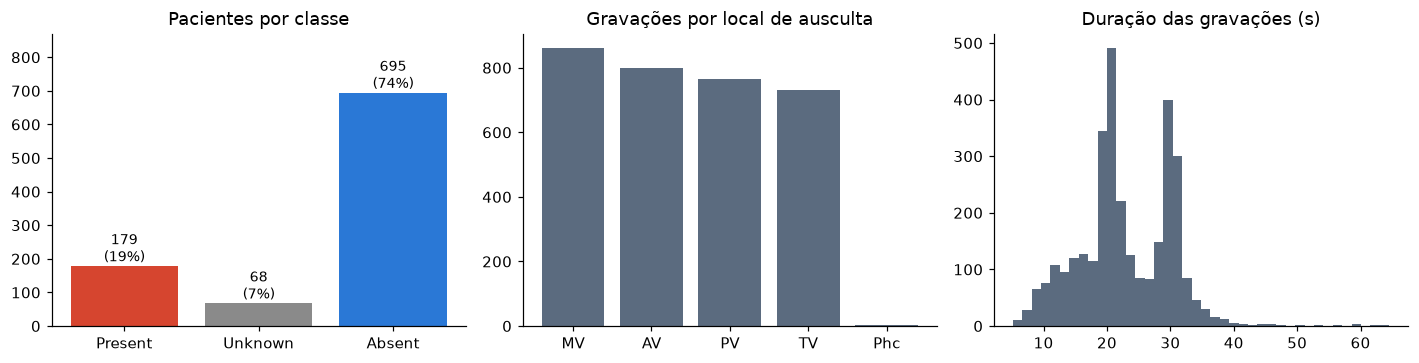

count    3163.0
mean       22.9
std         7.3
min         5.2
25%        19.1
50%        21.5
75%        29.4
max        64.5


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))

pc = patients["murmur"].value_counts().reindex(CLASSES)
axes[0].bar(pc.index, pc.values, color=[COLORS[c] for c in pc.index])
axes[0].set_title("Pacientes por classe")
for i, v in enumerate(pc.values): axes[0].text(i, v, f"{v}\n({v/pc.sum():.0%})", ha="center", va="bottom", fontsize=9)
axes[0].set_ylim(0, pc.max() * 1.25)

loc = manifest["location"].value_counts()
axes[1].bar(loc.index, loc.values, color="#5b6b7f")
axes[1].set_title("Gravações por local de ausculta")

axes[2].hist(manifest["duration_s"], bins=40, color="#5b6b7f")
axes[2].set_title("Duração das gravações (s)")
plt.tight_layout(); plt.show()
print(manifest["duration_s"].describe().round(1).to_string())

**O que isso mostra:** a base é muito desbalanceada (maioria Absent, Unknown é a menor
classe) e as durações variam bastante (de ~5 s a mais de 60 s). Por isso o pipeline
corta as gravações em **janelas de tamanho fixo**, e a avaliação usa a acurácia
ponderada, que pesa Present 5x, Unknown 3x e Absent 1x.

## 2. Do sinal bruto ao log-mel (`src/features.py`)

Etapas por gravação:

1. `load_audio`: lê o `.wav` (4000 Hz, mono);
2. `bandpass`: Butterworth de 4ª ordem, fase zero, 25–800 Hz;
3. `normalize_amplitude`: média zero e desvio-padrão 1 (o ganho do estetoscópio deixa de importar);
4. `logmel`: espectrograma log-mel, 64 bandas, janela de 50 ms, passo de 10 ms (100 quadros/s).

Vamos escolher uma gravação com sopro **Present** e seguir cada etapa.

In [5]:
# Paciente Present, no local onde o sopro é audível
present = manifest[(manifest["murmur"] == "Present") & (manifest["murmur_audible"])]
rec = present.iloc[0]
print(rec[["patient_id", "recording_id", "location", "duration_s", "murmur", "label"]].to_string())

raw = features.load_audio(rec["wav"])
print(f"\nsinal bruto: {raw.shape[0]} amostras, sr={features.SR} Hz, min={raw.min():.3f}, max={raw.max():.3f}")

patient_id         13918
recording_id    13918_TV
location              TV
duration_s         6.592
murmur           Present
label            Present

sinal bruto: 26368 amostras, sr=4000 Hz, min=-1.000, max=1.000


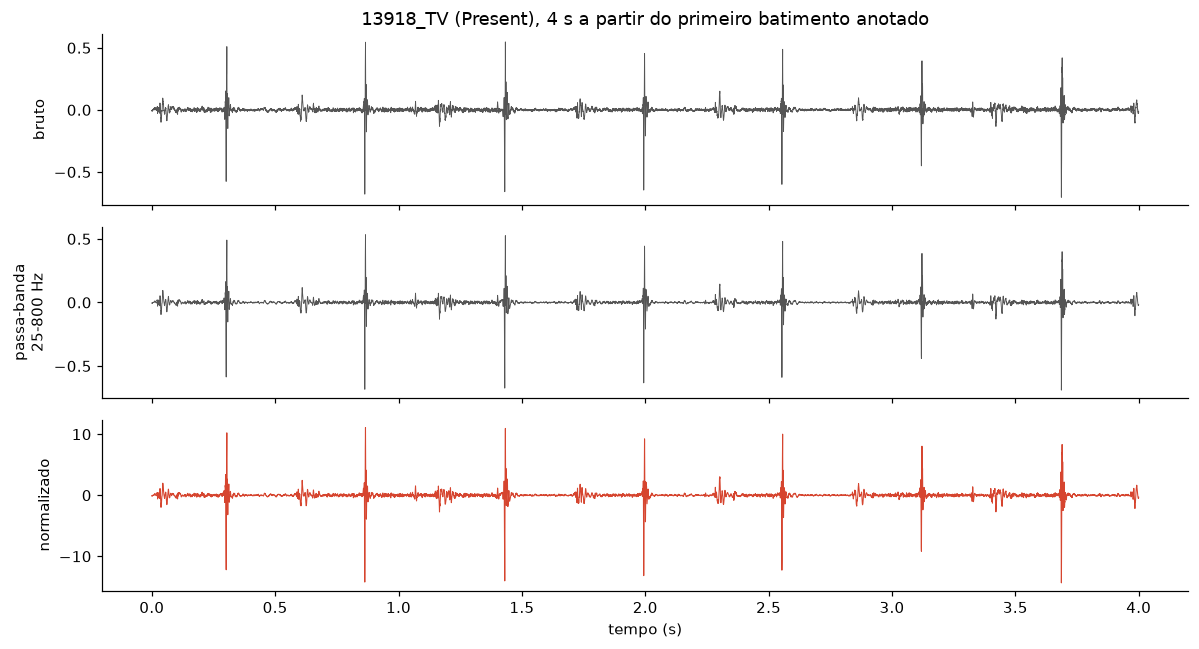

In [6]:
filtered = features.bandpass(raw)
clean = features.normalize_amplitude(filtered)
assert np.allclose(clean, features.preprocess_signal(raw), atol=1e-5)   # preprocess_signal = bandpass + normalize

t0 = rec["ann_start_s"] if not np.isnan(rec["ann_start_s"]) else 0.0
a, b = int(t0 * features.SR), int((t0 + 4) * features.SR)
t = np.arange(b - a) / features.SR

fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
axes[0].plot(t, raw[a:b], lw=0.6, color="#555"); axes[0].set_ylabel("bruto")
axes[1].plot(t, filtered[a:b], lw=0.6, color="#555"); axes[1].set_ylabel("passa-banda\n25-800 Hz")
axes[2].plot(t, clean[a:b], lw=0.7, color=COLORS["Present"]); axes[2].set_ylabel("normalizado")
axes[2].set_xlabel("tempo (s)")
axes[0].set_title(f"{rec['recording_id']} ({rec['murmur']}), 4 s a partir do primeiro batimento anotado")
plt.tight_layout(); plt.show()

**Por que 25–800 Hz?** Sons cardíacos ficam em ~25–200 Hz e sopros, mesmo agudos, chegam a algumas
centenas de Hz. Abaixo de 25 Hz é ruído de movimento/manuseio; acima de 800 Hz é quase só ruído.
O espectro abaixo confirma o efeito do filtro.

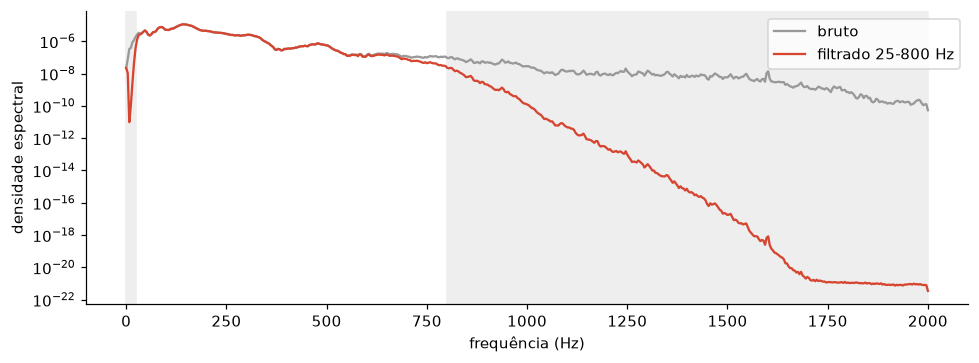

In [7]:
from scipy.signal import welch
f, p_raw = welch(raw, fs=features.SR, nperseg=1024)
_, p_fil = welch(filtered, fs=features.SR, nperseg=1024)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.semilogy(f, p_raw, label="bruto", color="#999")
ax.semilogy(f, p_fil, label="filtrado 25-800 Hz", color=COLORS["Present"])
ax.axvspan(0, 25, color="#eee"); ax.axvspan(800, 2000, color="#eee")
ax.set_xlabel("frequência (Hz)"); ax.set_ylabel("densidade espectral"); ax.legend()
plt.tight_layout(); plt.show()

log-mel: (64, 660) -> 6.6 s a 100 quadros/s


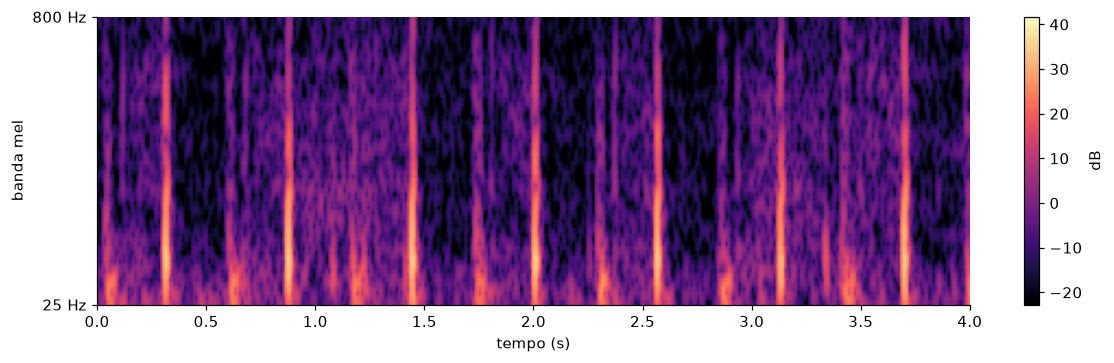

In [8]:
spec = features.logmel(clean)          # (64 bandas, quadros)
print("log-mel:", spec.shape, f"-> {spec.shape[1] / features.FRAMES_PER_SECOND:.1f} s a {features.FRAMES_PER_SECOND:.0f} quadros/s")
assert np.allclose(spec, features.recording_logmel(rec["wav"]), atol=1e-4)   # pipeline completo numa chamada

fr0, fr1 = int(t0 * 100), int((t0 + 4) * 100)
fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(spec[:, fr0:fr1], origin="lower", aspect="auto", extent=(0, 4, 0, 64),
               cmap="magma", vmin=np.percentile(spec, 5), vmax=spec.max())
ax.set_yticks([0, 64], ["25 Hz", "800 Hz"]); ax.set_xlabel("tempo (s)"); ax.set_ylabel("banda mel")
plt.colorbar(im, label="dB"); plt.tight_layout(); plt.show()

A mesma matriz `(64, quadros)` alimenta os dois modelos previstos: a **CNN** lê uma janela como imagem
`(1, 64, 400)`; a **RNN** lê como sequência de 400 vetores de 64 dimensões.

### Comparação rápida Absent × Present

Duas gravações de pacientes diferentes, mesmo pipeline.

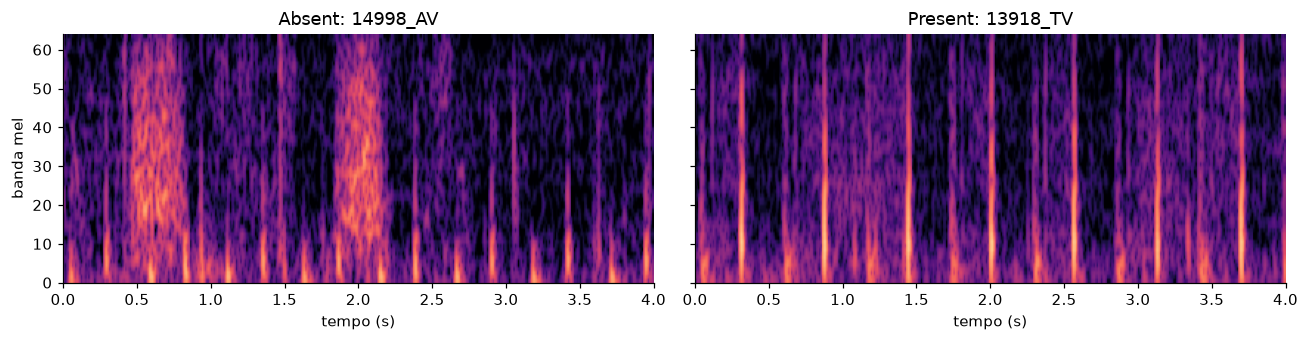

In [9]:
absent = manifest[manifest["murmur"] == "Absent"].iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for ax, r in zip(axes, [absent, rec]):
    s = features.recording_logmel(r["wav"])
    st = 0 if np.isnan(r["ann_start_s"]) else int(r["ann_start_s"] * 100)
    ax.imshow(s[:, st:st + 400], origin="lower", aspect="auto", extent=(0, 4, 0, 64), cmap="magma",
              vmin=np.percentile(s, 5), vmax=s.max())
    ax.set_title(f"{r['murmur']}: {r['recording_id']}"); ax.set_xlabel("tempo (s)")
axes[0].set_ylabel("banda mel")
plt.tight_layout(); plt.show()

## 3. MFCC como feature alternativa

`mfcc_from_logmel` aplica a DCT ao log-mel e fica com 20 coeficientes, mais 20 deltas (variação no tempo),
totalizando 40 linhas. É uma das variantes de pré-processamento a comparar na validação.

log-mel: (64, 660) | MFCC + deltas: (40, 660)
n_features('logmel') = 64 | n_features('mfcc') = 40


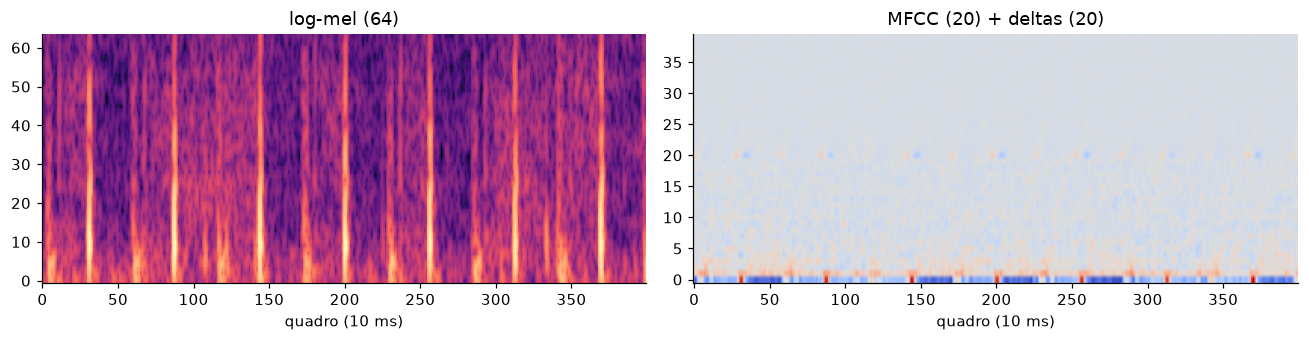

In [10]:
mfcc = features.mfcc_from_logmel(spec)
print("log-mel:", spec.shape, "| MFCC + deltas:", mfcc.shape)
print("n_features('logmel') =", features.n_features("logmel"), "| n_features('mfcc') =", features.n_features("mfcc"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].imshow(spec[:, fr0:fr1], origin="lower", aspect="auto", cmap="magma"); axes[0].set_title("log-mel (64)")
axes[1].imshow(mfcc[:, fr0:fr1], origin="lower", aspect="auto", cmap="coolwarm"); axes[1].set_title("MFCC (20) + deltas (20)")
for ax in axes: ax.set_xlabel("quadro (10 ms)")
plt.tight_layout(); plt.show()

## 4. Rótulo por paciente vs rótulo por gravação (`src/data.py`)

O enunciado exige **uma predição por paciente**. Mas um paciente Present muitas vezes tem sopro audível só em
alguns locais (`Murmur locations`). Treinar com "Present" em todas as gravações ensinaria o modelo que um som
normal é sopro. Então, **no treino**, `recording_label` marca como Absent a gravação de um paciente Present
em um local onde o sopro não foi ouvido. Unknown e Absent repassam o rótulo para todas as gravações.
A avaliação usa sempre o rótulo do paciente.

In [11]:
ex = manifest[manifest["murmur"] == "Present"].merge(patients[["patient_id", "murmur_locations"]], on="patient_id")
pid = ex.groupby("patient_id").filter(lambda g: g["murmur_audible"].nunique() == 2)["patient_id"].iloc[0]
print(f"Paciente {pid}, rótulo do paciente = Present")
ex[ex["patient_id"] == pid][["recording_id", "location", "murmur_locations", "murmur_audible", "label"]]

Paciente 13918, rótulo do paciente = Present


,recording_id,location,murmur_locations,murmur_audible,label
0,13918_AV,AV,TV,False,Absent
1,13918_PV,PV,TV,False,Absent
2,13918_TV,TV,TV,True,Present
3,13918_MV,MV,TV,False,Absent


In [12]:
print("Rótulo do paciente vs rótulo de treino por gravação:")
pd.crosstab(manifest["murmur"], manifest["label"]).reindex(index=CLASSES, columns=CLASSES)

Rótulo do paciente vs rótulo de treino por gravação:


label,Present,Unknown,Absent
murmur,,,
Present,499,0,117
Unknown,0,156,0
Absent,0,0,2391


Repare que a linha *Present* perde gravações para a coluna *Absent*: são as gravações de locais sem sopro audível.

## 5. Split por paciente

`make_patient_split`: 70/15/15, estratificado por `Murmur`, `seed=42`. O arquivo `splits/patient_split.csv`
é versionado: **todo o grupo treina e avalia nos mesmos pacientes**. Dividir por paciente (e não por gravação)
evita vazamento, já que gravações do mesmo paciente são muito parecidas.

In [13]:
split = data.load_split()
print(split.shape)
tab = pd.crosstab(split["split"], split["murmur"]).reindex(index=["train", "val", "test"], columns=CLASSES)
tab["total"] = tab.sum(axis=1)
display(tab)
display((tab[list(CLASSES)].div(tab["total"], axis=0) * 100).round(1).add_suffix(" %"))

(942, 3)


murmur,Present,Unknown,Absent,total
split,,,,
train,125,48,485,658
val,27,10,105,142
test,27,10,105,142


murmur,Present %,Unknown %,Absent %
split,,,
train,19.0,7.3,73.7
val,19.0,7.0,73.9
test,19.0,7.0,73.9


In [14]:
# Verificações de integridade do split
sets = {s: set(split.loc[split["split"] == s, "patient_id"]) for s in ["train", "val", "test"]}
assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"])
assert set(manifest["patient_id"]) == set(split["patient_id"])
# todas as gravações de um paciente caem no mesmo conjunto
rec_split = manifest.merge(split[["patient_id", "split"]], on="patient_id")
assert rec_split.groupby("patient_id")["split"].nunique().max() == 1
print("OK: nenhum paciente em dois conjuntos; recordings de cada paciente ficam juntas.")

# reproduz o split a partir da semente
again = data.make_patient_split(patients, val_size=0.15, test_size=0.15, seed=42)
print("make_patient_split(seed=42) reproduz o arquivo versionado:", again.equals(split))

OK: nenhum paciente em dois conjuntos; recordings de cada paciente ficam juntas.


make_patient_split(seed=42) reproduz o arquivo versionado: True


## 6. Cache e estatísticas de normalização (`src/preprocess.py`)

`python -m src.preprocess` (cerca de 20 s) faz três coisas, todas só lidas aqui:

- salva um log-mel por gravação em `data/cache/band25-800/logmel/<recording_id>.npy`;
- cria o split, se ainda não existir;
- calcula média e desvio **por linha** do log-mel e do MFCC usando **só as gravações de treino**, em
  `logmel_stats.npz` e `mfcc_stats.npz`. Usar só o treino evita que informação de validação/teste entre na normalização.

variante: band25-800
arquivos no cache: ['logmel', 'logmel_stats.npz', 'mfcc_stats.npz']
log-mel em cache: 3163 arquivos
variantes de banda em cache: ['band25-400', 'band25-800']


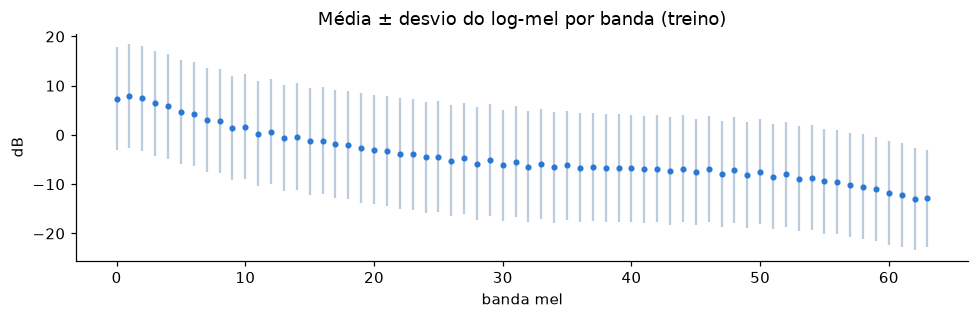

In [15]:
variant = features.variant_name()
print("variante:", variant)
print("arquivos no cache:", sorted(p.name for p in (CACHE_DIR / variant).iterdir()))
print("log-mel em cache:", len(list((CACHE_DIR / variant / "logmel").glob("*.npy"))), "arquivos")
print("variantes de banda em cache:", sorted(p.name for p in CACHE_DIR.iterdir() if p.is_dir()))

mean, std = data.load_feature_stats("logmel")
fig, ax = plt.subplots(figsize=(9, 3))
ax.errorbar(range(64), mean, yerr=std, fmt="o", ms=3, color="#2a78d6", ecolor="#bcd")
ax.set_xlabel("banda mel"); ax.set_ylabel("dB"); ax.set_title("Média ± desvio do log-mel por banda (treino)")
plt.tight_layout(); plt.show()

## 7. `WindowDataset`: janelas prontas para a rede

Cada item é `(x, y, rec_idx)`:

- `x`: janela `(64, 400)` (4 s a 100 quadros/s), já padronizada com as estatísticas do treino;
- `y`: índice da classe do **rótulo da gravação** (`Present=0, Unknown=1, Absent=2`);
- `rec_idx`: de qual gravação veio a janela, usado depois para agregar por gravação e por paciente.

As janelas avançam de 2 s em 2 s (`window_starts`); uma janela extra alinhada ao fim evita perder o final.

In [16]:
print("window_starts(n_frames=1030, win=400, hop=200) ->", data.window_starts(1030, 400, 200))

train_rec = data.get_split_manifest(manifest, split, "train")
val_rec = data.get_split_manifest(manifest, split, "val")
test_rec = data.get_split_manifest(manifest, split, "test")

train_ds = data.WindowDataset(train_rec, window_s=4.0, hop_s=2.0)
val_ds = data.WindowDataset(val_rec)
test_ds = data.WindowDataset(test_rec)
print(f"janelas: treino {len(train_ds)}, val {len(val_ds)}, teste {len(test_ds)}")

x, y, i = train_ds[0]
print("uma janela:", tuple(x.shape), x.dtype, "| classe:", CLASSES[y], "| gravação:", train_ds.recordings.loc[i, "recording_id"])
print(f"padronizada: média {x.mean():.2f}, desvio {x.std():.2f}")

window_starts(n_frames=1030, win=400, hop=200) -> [0, 200, 400, 600, 630]


janelas: treino 24153, val 5218, teste 5201
uma janela: (64, 400) torch.float32 | classe: Absent | gravação: 13918_AV
padronizada: média 0.00, desvio 0.79


In [17]:
from torch.utils.data import DataLoader
loader = DataLoader(train_ds, batch_size=64, shuffle=True)
xb, yb, ib = next(iter(loader))
print("batch:", tuple(xb.shape), "-> (batch, bandas, quadros)")
print("para CNN 2D :", tuple(xb.unsqueeze(1).shape), "-> (batch, 1, 64, 400)")
print("para RNN    :", tuple(xb.transpose(1, 2).shape), "-> (batch, 400 passos, 64 features)")
print("train_ds.n_features =", train_ds.n_features)

batch: (64, 64, 400) -> (batch, bandas, quadros)
para CNN 2D : (64, 1, 64, 400) -> (batch, 1, 64, 400)
para RNN    : (64, 400, 64) -> (batch, 400 passos, 64 features)
train_ds.n_features = 64


In [18]:
# Desbalanceamento visto pelo modelo: janelas por classe em cada conjunto
rows = []
for name, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    lab = np.array([ds.labels[r] for r in ds.window_recordings()])
    rows.append(pd.Series({c: (lab == k).sum() for k, c in enumerate(CLASSES)}, name=name))
win_tab = pd.DataFrame(rows)
display(win_tab)
print("Peso sugerido por classe no treino (inverso da frequência):")
w = 1 / win_tab.loc["train"]; print((w / w.sum() * 3).round(2).to_dict())

,Present,Unknown,Absent
train,3867,1151,19135
val,751,260,4207
test,805,251,4145


Peso sugerido por classe no treino (inverso da frequência):
{'Present': 0.66, 'Unknown': 2.21, 'Absent': 0.13}


### Variantes de pré-processamento

Cada escolha é um argumento do `WindowDataset`, para compararmos **na validação**, mudando uma coisa por vez:

In [19]:
variants = {
    "padrão (logmel, 4 s)":       dict(),
    "janela 2 s / passo 1 s":     dict(window_s=2.0, hop_s=1.0),
    "janela 6 s / passo 3 s":     dict(window_s=6.0, hop_s=3.0),
    "MFCC + deltas":              dict(feature="mfcc"),
    "corte nas bordas sem anotação (só treino)": dict(trim_to_annotation=True),
}
rows = []
for name, kw in variants.items():
    ds = data.WindowDataset(train_rec, **kw)
    rows.append({"variante": name, "janelas": len(ds), "formato de x": tuple(ds[0][0].shape)})
pd.DataFrame(rows)

,variante,janelas,formato de x
0,"padrão (logmel, 4 s)",24153,"(64, 400)"
1,janela 2 s / passo 1 s,49413,"(64, 200)"
2,janela 6 s / passo 3 s,15695,"(64, 600)"
3,MFCC + deltas,24153,"(40, 400)"
4,corte nas bordas sem anotação (só treino),14795,"(64, 400)"


In [20]:
bands = sorted(p.name for p in CACHE_DIR.iterdir() if p.is_dir())
print("Bandas já em cache:", bands)
if "band25-400" in bands:
    ds = data.WindowDataset(train_rec, band=(25, 400))
    print("Banda 25-400 Hz:", len(ds), "janelas, x =", tuple(ds[0][0].shape))

Bandas já em cache: ['band25-400', 'band25-800']


Banda 25-400 Hz: 24153 janelas, x = (64, 400)


## 8. Avaliação (`src/evaluate.py`)

### 8.1 Acurácia ponderada e matriz de confusão

Métrica do PhysioNet 2022, ao nível do paciente:

$$WA = \frac{5\,m_{PP} + 3\,m_{UU} + m_{AA}}{5(m_{PP}+m_{UP}+m_{AP}) + 3(m_{PU}+m_{UU}+m_{AU}) + (m_{PA}+m_{UA}+m_{AA})}$$

onde `m_ij` = pacientes previstos como `i` cuja classe real é `j`. A matriz tem **linhas = previsto** e
**colunas = real**. Começamos pelos classificadores triviais, que servem de régua: um modelo só vale se bater
isso com folga.

In [21]:
labels = split.set_index("patient_id")["murmur"]      # rótulo real de cada paciente
val_labels = labels[split.loc[split["split"] == "val", "patient_id"]]

rows = {}
for c in CLASSES:
    m = evaluate.classification_metrics(val_labels.to_numpy(), np.full(len(val_labels), c))
    rows[f"sempre {c}"] = round(m["weighted_accuracy"], 3)
print("Acurácia ponderada dos classificadores triviais (validação):")
pd.Series(rows).to_frame("WA")

Acurácia ponderada dos classificadores triviais (validação):


,WA
sempre Present,0.500
sempre Unknown,0.111
sempre Absent,0.389


In [22]:
# Oráculo e um erro de exemplo, para ver a matriz e a métrica funcionando
y_true = val_labels.to_numpy()
perfect = evaluate.classification_metrics(y_true, y_true)
print("Previsão perfeita:", perfect["weighted_accuracy"])

y_pred = y_true.copy()
# os 5 primeiros Present viram Absent
idx = np.where(y_true == "Present")[0][:5]
y_pred[idx] = "Absent"
m = evaluate.classification_metrics(y_true, y_pred)
print(evaluate.format_metrics(m))
print("\nErrar 5 Present custa:", round(perfect["weighted_accuracy"] - m["weighted_accuracy"], 3), "de WA")

Previsão perfeita: 1.0
Weighted accuracy: 0.907
Accuracy: 0.965   macro F1: 0.958
Recall: Present 0.81  Unknown 1.00  Absent 1.00
              true Present  true Unknown  true Absent
pred Present            22             0            0
pred Unknown             0            10            0
pred Absent              5             0          105

Errar 5 Present custa: 0.093 de WA


### 8.2 De janela a paciente

Fluxo: **janela → gravação → paciente**.

1. `window_probabilities(model, dataset)` dá a probabilidade das 3 classes para cada janela;
2. `recording_probabilities` tira a **média** das janelas de cada gravação;
3. `patient_predictions` combina as gravações do paciente. Regra hierárquica (padrão): Present se *alguma*
   gravação tem P(Present) ≥ `t_present`; senão Unknown se alguma tem P(Unknown) ≥ `t_unknown`; senão Absent.
   Faz sentido porque o sopro pode ser audível em um único local. `rule="mean"` usa a média das gravações.
4. `tune_thresholds` escolhe `t_present` e `t_unknown` **na validação**; o teste só é usado no fim, com limiares fixos.

Ainda **não há modelo treinado** (`src/models.py` e `src/train.py` estão vazios). Para mostrar o fluxo funcionando,
usamos abaixo uma rede **sem treino** (pesos aleatórios), exatamente o caso que o README cita como alerta.

In [23]:
import tempfile
import torch, torch.nn as nn
torch.manual_seed(0)

untrained = nn.Sequential(nn.Flatten(), nn.Linear(64 * 400, 3))   # pesos aleatórios, nunca treinada

def rec_probs(ds):
    wp, wrec = evaluate.window_probabilities(untrained, ds)
    print(f"  {len(wp)} janelas -> prob. média por gravação ({len(ds.recordings)} gravações)")
    return evaluate.recording_probabilities(wp, wrec, len(ds.recordings))

print("val:");  val_rp = rec_probs(val_ds)
print("test:"); test_rp = rec_probs(test_ds)
pd.DataFrame(val_rp[:5], columns=[f"P({c})" for c in CLASSES]).assign(recording=val_ds.recordings["recording_id"][:5].values)

val:


  5218 janelas -> prob. média por gravação (474 gravações)
test:


  5201 janelas -> prob. média por gravação (479 gravações)


,P(Present),P(Unknown),P(Absent),recording
0,0.295036,0.362522,0.342442,2530_AV
1,0.256809,0.424152,0.319039,2530_PV
2,0.286278,0.317122,0.396600,2530_TV
3,0.405917,0.252638,0.341446,2530_MV
4,0.256538,0.351172,0.392290,31737_AV


In [24]:
# 1) limiares escolhidos SÓ na validação
t_p, t_u, val_wa = evaluate.tune_thresholds(val_rp, val_ds.recordings["patient_id"], labels)
print(f"limiares: t_present={t_p}, t_unknown={t_u}  (WA na validação, otimista: {val_wa:.3f})")

# 2) números finais no teste, com limiares fixos
pred = evaluate.patient_predictions(test_rp, test_ds.recordings["patient_id"], t_present=t_p, t_unknown=t_u)
print(f"\n{len(pred)} pacientes no teste, uma predição por paciente")
display(pred.head())

metrics = evaluate.evaluate_patients(pred, labels)
print(evaluate.format_metrics(metrics))

limiares: t_present=0.25, t_unknown=0.5  (WA na validação, otimista: 0.511)

142 pacientes no teste, uma predição por paciente


,patient_id,murmur,mean_p_Present,mean_p_Unknown,mean_p_Absent,max_p_Present,max_p_Unknown,max_p_Absent
0,14241,Present,0.425362,0.281836,0.292802,0.524785,0.339620,0.336583
1,14998,Present,0.456656,0.246367,0.296976,0.513576,0.294750,0.324803
2,33151,Present,0.309415,0.345874,0.344711,0.375504,0.419007,0.380693
3,36327,Present,0.379853,0.287672,0.332474,0.433482,0.311137,0.385367
4,39456,Present,0.357115,0.332652,0.310233,0.373656,0.364543,0.329028


Weighted accuracy: 0.500
Accuracy: 0.190   macro F1: 0.108
Recall: Present 1.00  Unknown 0.00  Absent 0.00
              true Present  true Unknown  true Absent
pred Present            27            10          102
pred Unknown             0             0            3
pred Absent              0             0            0


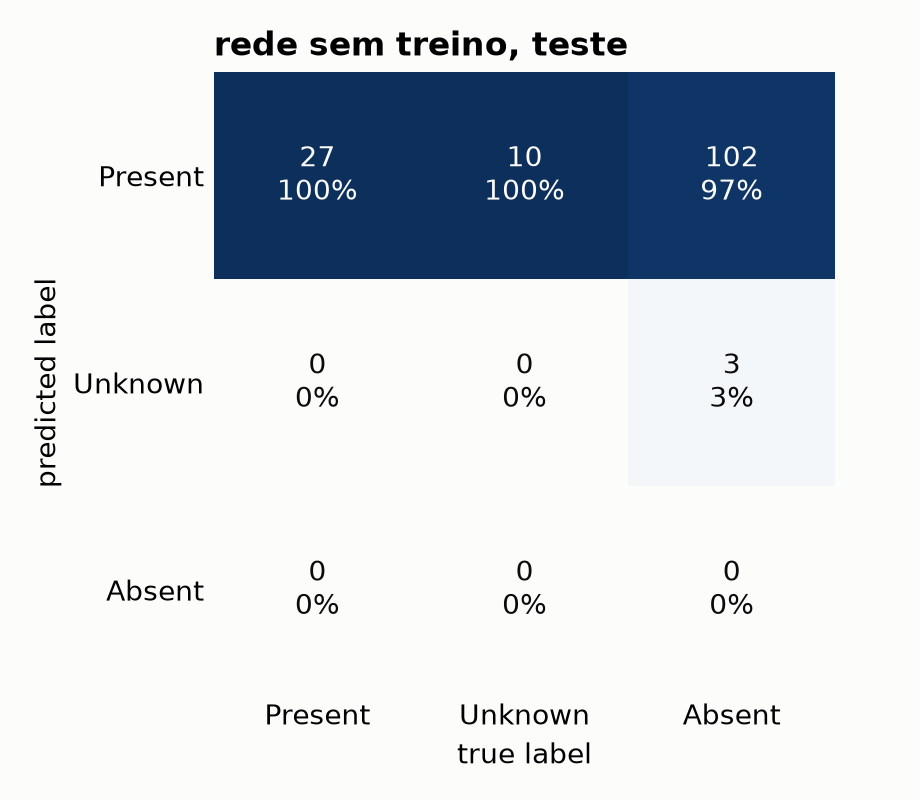

In [25]:
out = Path(tempfile.gettempdir()) / "cm_demo.png"
evaluate.plot_confusion_matrix(metrics["confusion_matrix"], out, "rede sem treino, teste")
from IPython.display import Image
Image(filename=str(out), width=420)

**Como ler isso:** esta rede aleatória marca ~0.5 porque a métrica premia prever Present: com limiares ajustados,
"quase tudo Present" já chega perto do 0.500 do classificador trivial. Por isso o README fixa a régua: um modelo só
é útil se ficar **claramente acima de ~0.55–0.60**. Esta seção prova que o *encanamento* de avaliação funciona; os
números que importam virão quando houver modelos treinados.

### 8.3 Regras de agregação e arquivo de submissão

In [26]:
pred_mean = evaluate.patient_predictions(test_rp, test_ds.recordings["patient_id"], rule="mean")
print("Regra hierárquica :", round(metrics["weighted_accuracy"], 3))
print("Regra da média    :", round(evaluate.evaluate_patients(pred_mean, labels)["weighted_accuracy"], 3))

# formato do CSV de submissão (patient_id, murmur); escrito em arquivo temporário para não poluir submission/
tmp = Path(tempfile.gettempdir()) / "predictions_demo.csv"
evaluate.save_submission(pred, tmp)
print("\n", tmp.read_text().splitlines()[:4], "...")

Regra hierárquica : 0.5
Regra da média    : 0.481

 ['patient_id,murmur', '14241,Present', '14998,Present', '33151,Present'] ...


## Resumo: o que já existe e o que falta

| Etapa | Estado |
|---|---|
| Leitura, rótulos e manifesto (`data.py`) | feito |
| Filtro, normalização, log-mel e MFCC (`features.py`) | feito |
| Cache, estatísticas só do treino (`preprocess.py`) | feito |
| Split 70/15/15 por paciente, versionado | feito |
| `WindowDataset` com variantes de pré-processamento | feito |
| Métrica oficial, agregação por paciente, limiares na validação (`evaluate.py`) | feito |
| Modelos (`models.py`): escolher 2 entre MLP / CNN / RNN | **a fazer** |
| Treino (`train.py`): perda com pesos de classe, otimizador, early stopping | **a fazer** |
| Comparar variantes de pré-processamento na validação | **a fazer** |
| Avaliação final no teste + previsões nos dados ocultos | **a fazer** |
| Slides e autoavaliação | **a fazer** |